In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import fabio
import matplotlib.patches as patches

In [4]:
data_dir_1 = r"C:\Users\j.bantol\Documents\Data\XRR\experiment\IHE-1\gao_sto_01.3\2026-06-29_gao_sto01.3\12_EIGER351x351-2Dsnapshot_XRR_0-0.3deg_0.005deg_1s_FrameFiles"
data_dir_2 = r"C:\Users\j.bantol\Documents\Data\XRR\experiment\IHE-1\gao_sto_01.3\2026-06-29_gao_sto01.3\13_EIGER351x351-2Dsnapshot_XRR_0.3-4deg_0.005deg_5s_FrameFiles"

# counting time per frame, used to normalize counts -> cps
count_time_1 = 1   # s, data_dir_1
count_time_2 = 5   # s, data_dir_2

Found 61 frames


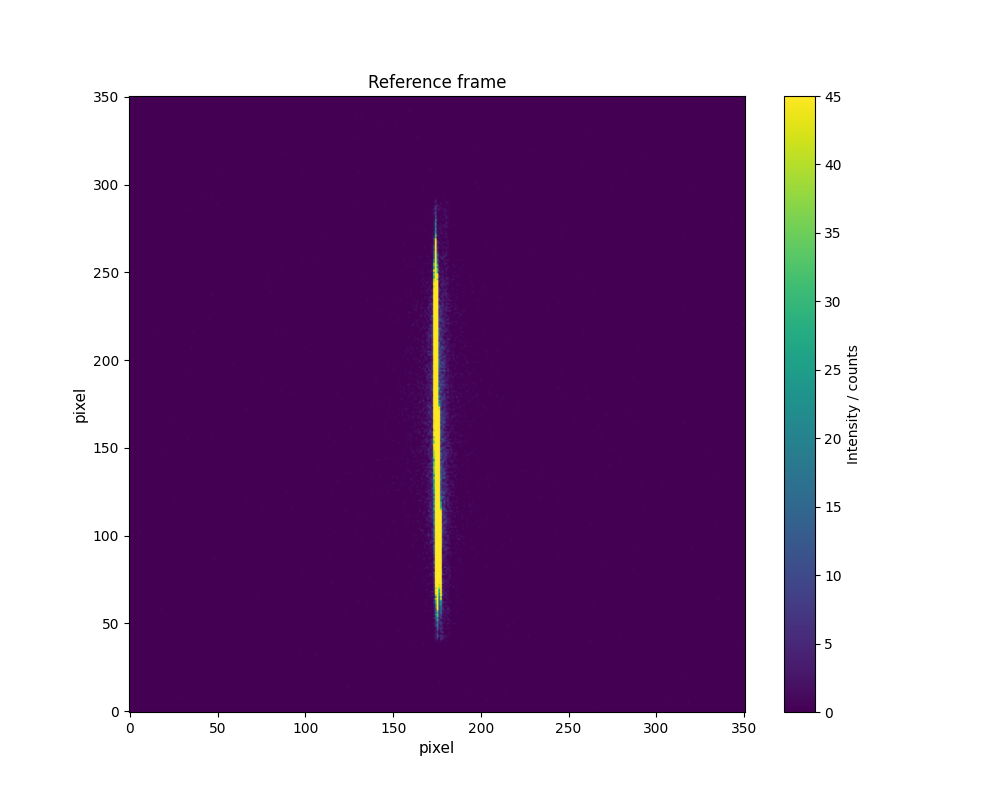

In [26]:
%matplotlib widget
plt.close("all")

frames = sorted([f for f in os.listdir(data_dir_1) if f.endswith((".gfrm"))])
print(f"Found {len(frames)} frames")

# step 1: plot reference frame to choose ROI
ref_obj = fabio.open(os.path.join(data_dir_1, frames[60]))
ref_data = ref_obj.data

fig, ax = plt.subplots(figsize=(10, 8))
img = ax.imshow(ref_data, vmax=np.percentile(ref_data, 99.5), origin="lower", cmap="viridis")
plt.colorbar(img, ax=ax, label="Intensity / counts")


ax.set_title(f"Reference frame", fontsize="12")
ax.set_xlabel(f"pixel", fontsize="11")
ax.set_ylabel(f"pixel", fontsize="11")
plt.show()

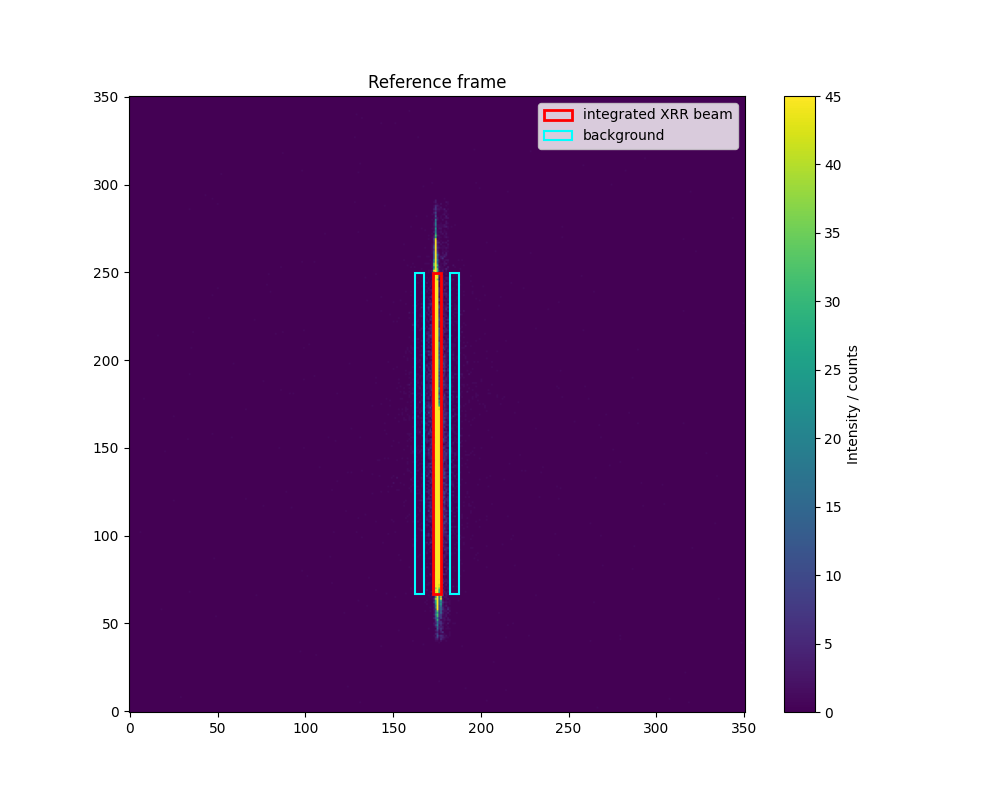

In [27]:
# step 2: set ROI manually
x0, x1 = 172.5, 177.5   # column range
y0, y1 = 66.5, 249.5   # row range

# bg ROIs: same width and y-range as signal, placed left and right
sig_width = x1 - x0
gap = 5

x0_bg_left  = x0 - gap - sig_width
x1_bg_left  = x0 - gap
x0_bg_right = x1 + gap
x1_bg_right = x1 + gap + sig_width
y0_bg, y1_bg = y0, y1

# verify ROI overlay
fig, ax = plt.subplots(figsize=(10, 8))
img=ax.imshow(ref_data, vmax=np.percentile(ref_data, 99.5), origin="lower")
plt.colorbar(img, ax=ax, label="Intensity / counts")

ax.add_patch(patches.Rectangle((x0, y0), x1-x0, y1-y0, linewidth=2, edgecolor="red", facecolor="none", label="integrated XRR beam"))
ax.add_patch(patches.Rectangle((x0_bg_left, y0_bg), sig_width, y1_bg-y0_bg,linewidth=1.5, edgecolor="cyan", facecolor="none", label="background"))
ax.add_patch(patches.Rectangle((x0_bg_right, y0_bg), sig_width, y1_bg-y0_bg,linewidth=1.5, edgecolor="cyan", facecolor="none"))
ax.legend(loc="upper right")
ax.set_title("Reference frame")
plt.show()

In [28]:
# step 3: apply ROI to all frames, extract 2theta, integrate ROI
x0, x1 = int(x0), int(x1)
y0, y1 = int(y0), int(y1)

x0_bg_left, x1_bg_left = int(x0_bg_left), int(x1_bg_left)
x0_bg_right, x1_bg_right = int(x0_bg_right), int(x1_bg_right)
y0_bg, y1_bg = int(y0_bg), int(y1_bg)

step_size = 0.005   # degrees per frame
start_angle = 0   # starting 2theta

results = []
for i, f in enumerate(frames):
    obj = fabio.open(os.path.join(data_dir_1, f))
    data = obj.data
    roi_sum = data[y0:y1, x0:x1].sum()
    
    sig   = data[y0:y1, x0:x1].sum()
    bg_l  = data[y0_bg:y1_bg, x0_bg_left:x1_bg_left].sum()
    bg_r  = data[y0_bg:y1_bg, x0_bg_right:x1_bg_right].sum()
    bg_avg = (bg_l + bg_r) / 2

    two_theta = start_angle + i * step_size
    results.append((two_theta, sig, bg_avg))

two_thetas_1 = np.array([r[0] for r in results])
roi_sums_1 = np.array([r[1] for r in results])
bg_avgs_1 = np.array([r[2] for r in results])

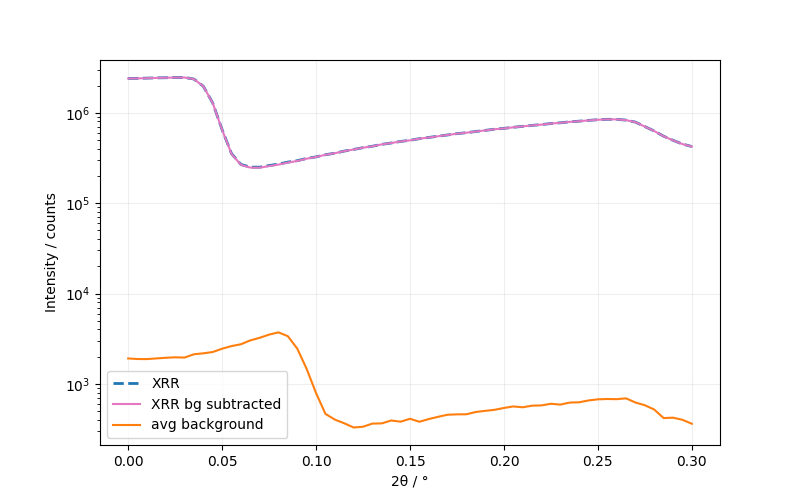

In [29]:
# step 4: plot ROI intensity vs. scattering angle
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(two_thetas_1, roi_sums_1, "--", lw=2, color="C0", label="XRR")
ax.plot(two_thetas_1, roi_sums_1 - bg_avgs_1, color="C6", label="XRR bg subtracted")
ax.plot(two_thetas_1, bg_avgs_1, color="C1", label="avg background")

ax.set_xlabel("2θ / °")
ax.set_ylabel("Intensity / counts")
ax.set_yscale("log")

plt.grid(True, alpha=0.2)
plt.legend()
plt.show()

Found 741 frames


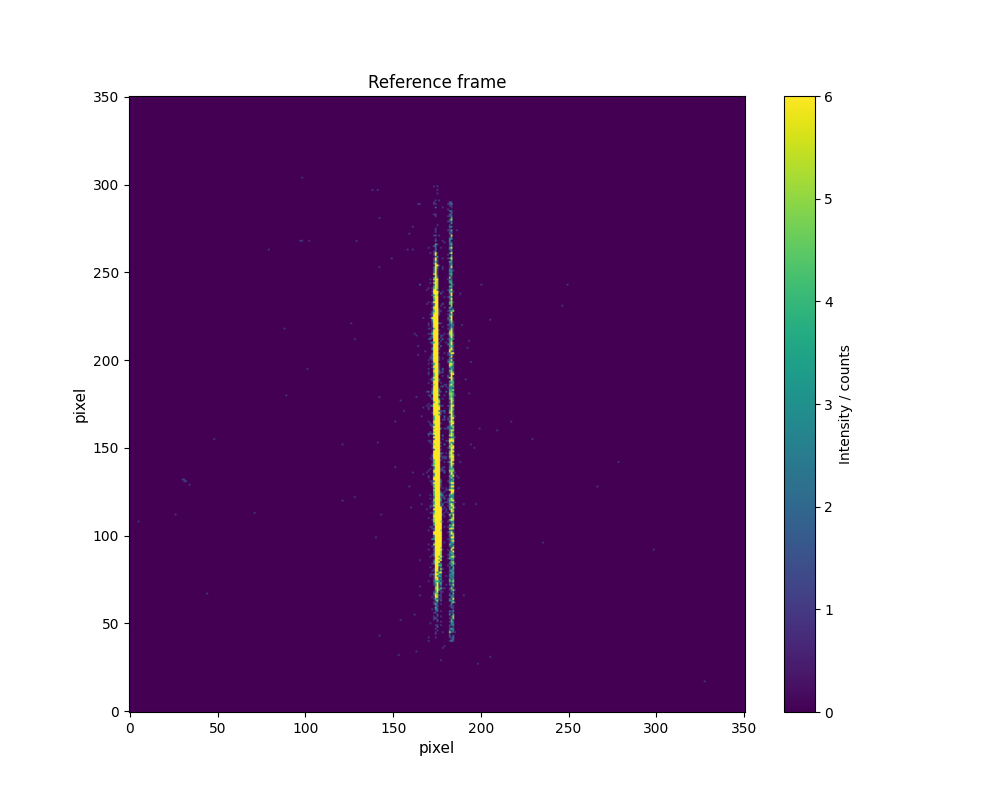

In [30]:
plt.close("all")

frames = sorted([f for f in os.listdir(data_dir_2) if f.endswith((".gfrm"))])
print(f"Found {len(frames)} frames")

# step 1: plot reference frame to choose ROI
ref_obj = fabio.open(os.path.join(data_dir_2, frames[50]))
ref_data = ref_obj.data

fig, ax = plt.subplots(figsize=(10, 8))
img = ax.imshow(ref_data, vmax=np.percentile(ref_data, 99.5), origin="lower", cmap="viridis")
plt.colorbar(img, ax=ax, label="Intensity / counts")


ax.set_title(f"Reference frame", fontsize="12")
ax.set_xlabel(f"pixel", fontsize="11")
ax.set_ylabel(f"pixel", fontsize="11")
plt.show()

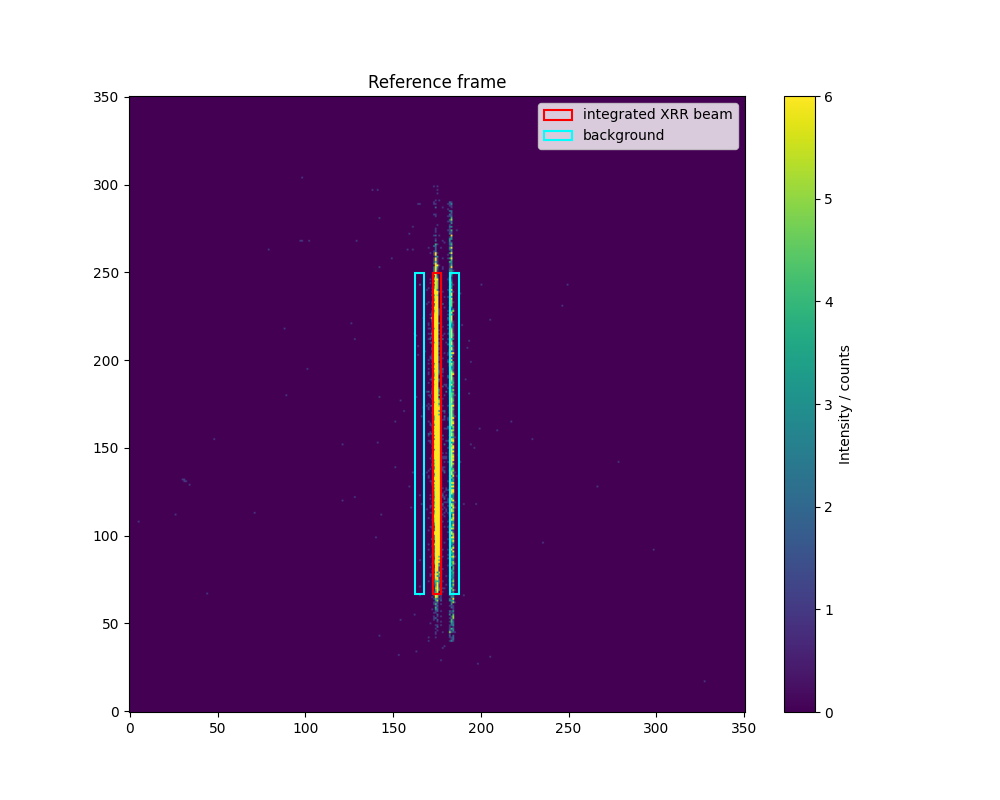

In [31]:
# step 2: set ROI manually
x0, x1 = 172.5, 177.5   # column range
y0, y1 = 66.5, 249.5   # row range

# bg ROIs: same width and y-range as signal, placed left and right
sig_width = x1 - x0
gap = 5

x0_bg_left  = x0 - gap - sig_width
x1_bg_left  = x0 - gap
x0_bg_right = x1 + gap
x1_bg_right = x1 + gap + sig_width
y0_bg, y1_bg = y0, y1

# verify ROI overlay
fig, ax = plt.subplots(figsize=(10, 8))
img=ax.imshow(ref_data, vmax=np.percentile(ref_data, 99.5), origin="lower")
plt.colorbar(img, ax=ax, label="Intensity / counts")

ax.add_patch(patches.Rectangle((x0, y0), x1-x0, y1-y0, linewidth=1.5, edgecolor="red", facecolor="none", label="integrated XRR beam"))
ax.add_patch(patches.Rectangle((x0_bg_left, y0_bg), sig_width, y1_bg-y0_bg,linewidth=1.5, edgecolor="cyan", facecolor="none", label="background"))
ax.add_patch(patches.Rectangle((x0_bg_right, y0_bg), sig_width, y1_bg-y0_bg,linewidth=1.5, edgecolor="cyan", facecolor="none"))
ax.legend(loc="upper right")
ax.set_title("Reference frame")
plt.show()

In [32]:
# step 3: apply ROI to all frames, extract 2theta, integrate ROI
x0, x1 = int(x0), int(x1)
y0, y1 = int(y0), int(y1)

x0_bg_left, x1_bg_left = int(x0_bg_left), int(x1_bg_left)
x0_bg_right, x1_bg_right = int(x0_bg_right), int(x1_bg_right)
y0_bg, y1_bg = int(y0_bg), int(y1_bg)

step_size = 0.005   # degrees per frame
start_angle = 0.3   # starting 2theta

results = []
for i, f in enumerate(frames):
    obj = fabio.open(os.path.join(data_dir_2, f))
    data = obj.data
    roi_sum = data[y0:y1, x0:x1].sum()
    
    sig   = data[y0:y1, x0:x1].sum()
    bg_l  = data[y0_bg:y1_bg, x0_bg_left:x1_bg_left].sum()
    bg_r  = data[y0_bg:y1_bg, x0_bg_right:x1_bg_right].sum()
    bg_avg = (bg_l + bg_r) / 2

    two_theta = start_angle + i * step_size
    results.append((two_theta, sig, bg_avg))

two_thetas_2 = np.array([r[0] for r in results])
roi_sums_2 = np.array([r[1] for r in results])
bg_avgs_2 = np.array([r[2] for r in results])

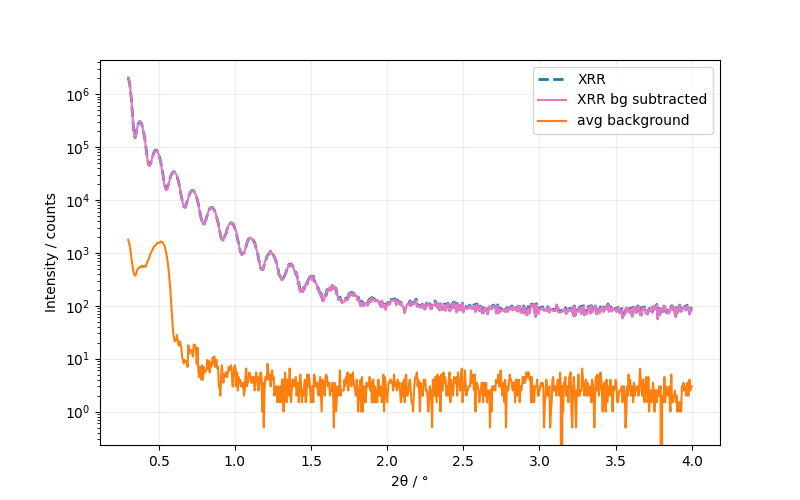

In [33]:
# step 4: plot ROI intensity vs. scattering angle
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(two_thetas_2, roi_sums_2, "--", lw=2, color="C0", label="XRR")
ax.plot(two_thetas_2, roi_sums_2 - bg_avgs_2, color="C6", label="XRR bg subtracted")
ax.plot(two_thetas_2, bg_avgs_2, color="C1", label="avg background")

ax.set_xlabel("2θ / °")
ax.set_ylabel("Intensity / counts")
ax.set_yscale("log")

plt.grid(True, alpha=0.2)
plt.legend()
plt.show()

In [ ]:
# combine both scans and normalize counts -> cps (counts / counting time per frame)
two_thetas = np.concatenate([two_thetas_1, two_thetas_2])
roi_sums = np.concatenate([roi_sums_1 / count_time_1, roi_sums_2 / count_time_2])
bg_avgs = np.concatenate([bg_avgs_1 / count_time_1, bg_avgs_2 / count_time_2])

# sort by 2theta so the line is continuous across the 0.3° stitch point
order = np.argsort(two_thetas, kind="stable")
two_thetas, roi_sums, bg_avgs = two_thetas[order], roi_sums[order], bg_avgs[order]

In [ ]:
# step 5: plot combined, normalized ROI intensity vs. scattering angle
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(two_thetas, roi_sums - bg_avgs, lw=2, color="C6", label="XRR bg subtracted")
ax.plot(two_thetas, roi_sums, "--", color="red", label="XRR")
ax.plot(two_thetas, bg_avgs, color="skyblue", label="avg background")
ax.axvline(two_thetas_2[0], color="gray", ls=":", lw=1, label=f"scan stitch ({count_time_1} s → {count_time_2} s)")

ax.set_xlabel("2θ / °")
ax.set_ylabel("Intensity / cps")
ax.set_yscale("log")

plt.grid(True, alpha=0.2)
plt.legend()
plt.show()